In [1]:
from background.modules.exchange_upbit import ExChangeUpbit
from background.modules.exchange__calculator import ExChangeCalculator
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
import os

import datetime

In [2]:
interval = "minute5"
count = 200
days = 93

In [3]:
upbit = ExChangeUpbit()
upbit.set_ticker("KRW-BTC")

True

In [4]:


end_dt = datetime.datetime.now()
start_dt = end_dt - datetime.timedelta(days=days)

dfs = []
to = end_dt
max_call = int((days * 24 * 12) / count) + 2

for _ in range(max_call):
    df = upbit.get_ohlcv(
        interval=interval,
        date=to.strftime("%Y-%m-%d %H:%M:%S"),
        count=count
    )

    if df is None or df.empty:
        break

    dfs.append(df)

    oldest_dt = df["datetime"].iloc[0]

    # 30일 이전이면 종료
    if oldest_dt <= start_dt:
        break

    # 다음 호출 기준점
    to = oldest_dt - datetime.timedelta(minutes=5)

df_combined = (
    pd.concat(dfs)
    .drop_duplicates(subset="datetime")
    .sort_values("datetime")
    .reset_index(drop=True)
)

In [5]:
df_combined.head()

,open,high,low,close,volume,value,datetime
0,133825000.0,133825000.0,133685000.0,133694000.0,3.067879,4.102706e+08,2025-12-06 11:30:00
1,133694000.0,133775000.0,133688000.0,133766000.0,1.057729,1.414346e+08,2025-12-06 11:35:00
2,133766000.0,133766000.0,133651000.0,133720000.0,1.907620,2.550697e+08,2025-12-06 11:40:00
3,133652000.0,133720000.0,133621000.0,133621000.0,2.201924,2.942996e+08,2025-12-06 11:45:00
4,133621000.0,133720000.0,133613000.0,133719000.0,1.927246,2.575669e+08,2025-12-06 11:50:00


In [6]:
def apply_all_features(calculator):
    methods = [
        getattr(calculator, m)
        for m in dir(calculator)
        if callable(getattr(calculator, m))
        and m.startswith("set_")
        and m not in ["set_ohlcv"]
    ]
    
    for method in methods:
        try:
            method()
        except Exception:
            pass

    return calculator.get_df()

calculator = ExChangeCalculator(df_combined)
new_df = apply_all_features(calculator)
new_df.head(100)

,open,high,low,close,volume,value,datetime,atr,atr_ratio,cdlengulfing,...,volume_volatility,volume_zscore_20,cum_volume,cum_vwap,vwap,weekday,weekday_cos,weekday_num,weekday_sin,wick_ratio
0,133825000.0,133825000.0,133685000.0,133694000.0,3.067879,4.102706e+08,2025-12-06 11:30:00,140000.000000,0.001047,0,...,NaN,NaN,3.067879,4.102817e+08,1.337347e+08,5,-0.222521,5,-0.974928,0.064286
1,133694000.0,133775000.0,133688000.0,133766000.0,1.057729,1.414346e+08,2025-12-06 11:35:00,136214.285714,0.001018,0,...,NaN,NaN,4.125607,5.517455e+08,1.337368e+08,5,-0.222521,5,-0.974928,0.172414
2,133766000.0,133766000.0,133651000.0,133720000.0,1.907620,2.550697e+08,2025-12-06 11:40:00,134698.979592,0.001007,0,...,NaN,NaN,6.033227,8.068179e+08,1.337291e+08,5,-0.222521,5,-0.974928,0.600000
3,133652000.0,133720000.0,133621000.0,133621000.0,2.201924,2.942996e+08,2025-12-06 11:45:00,132149.052478,0.000989,0,...,NaN,NaN,8.235152,1.101114e+09,1.337090e+08,5,-0.222521,5,-0.974928,0.686869
4,133621000.0,133720000.0,133613000.0,133719000.0,1.927246,2.575669e+08,2025-12-06 11:50:00,130352.691587,0.000975,0,...,NaN,NaN,10.162397,1.358756e+09,1.337043e+08,5,-0.222521,5,-0.974928,0.084112
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,134069000.0,134069000.0,133849000.0,133898000.0,2.377103,3.184222e+08,2025-12-06 19:25:00,146938.092979,0.001097,0,...,0.651051,0.406224,230.396706,3.090826e+10,1.341523e+08,5,-0.222521,5,-0.974928,0.222727
96,133898000.0,134017000.0,133821000.0,133920000.0,1.344935,1.800693e+08,2025-12-06 19:30:00,150442.514909,0.001123,0,...,0.618421,-0.319866,231.741641,3.108837e+10,1.341510e+08,5,-0.222521,5,-0.974928,0.887755
97,133924000.0,134052000.0,133866000.0,133920000.0,1.087963,1.457390e+08,2025-12-06 19:35:00,152982.335272,0.001142,0,...,0.599175,-0.570581,232.829604,3.123410e+10,1.341500e+08,5,-0.222521,5,-0.974928,0.978495
98,133920000.0,134028000.0,133920000.0,133972000.0,0.955984,1.280675e+08,2025-12-06 19:40:00,149769.311324,0.001118,0,...,0.615479,-0.741151,233.785588,3.136218e+10,1.341493e+08,5,-0.222521,5,-0.974928,0.518519


In [7]:
def create_target(df, horizon=12):  # 예: minute5 기준 12 = 1시간
    df = df.copy()
    df["future_close"] = df["close"].shift(-horizon)
    df["return"] = (df["future_close"] - df["close"]) / df["close"]

    df["target"] = 0
    df.loc[df["return"] >= 0.005, "target"] = 1
    df.loc[df["return"] <= -0.005, "target"] = -1

    #df = df.dropna()
    return df

new_df2 = create_target(new_df, 15)
new_df2.head(100)

,open,high,low,close,volume,value,datetime,atr,atr_ratio,cdlengulfing,...,cum_volume,cum_vwap,vwap,weekday,weekday_cos,weekday_num,weekday_sin,wick_ratio,return,target
0,133825000.0,133825000.0,133685000.0,133694000.0,3.067879,4.102706e+08,2025-12-06 11:30:00,140000.000000,0.001047,0,...,3.067879,4.102817e+08,1.337347e+08,5,-0.222521,5,-0.974928,0.064286,0.005819,1
1,133694000.0,133775000.0,133688000.0,133766000.0,1.057729,1.414346e+08,2025-12-06 11:35:00,136214.285714,0.001018,0,...,4.125607,5.517455e+08,1.337368e+08,5,-0.222521,5,-0.974928,0.172414,0.005255,1
2,133766000.0,133766000.0,133651000.0,133720000.0,1.907620,2.550697e+08,2025-12-06 11:40:00,134698.979592,0.001007,0,...,6.033227,8.068179e+08,1.337291e+08,5,-0.222521,5,-0.974928,0.600000,0.005609,1
3,133652000.0,133720000.0,133621000.0,133621000.0,2.201924,2.942996e+08,2025-12-06 11:45:00,132149.052478,0.000989,0,...,8.235152,1.101114e+09,1.337090e+08,5,-0.222521,5,-0.974928,0.686869,0.006257,1
4,133621000.0,133720000.0,133613000.0,133719000.0,1.927246,2.575669e+08,2025-12-06 11:50:00,130352.691587,0.000975,0,...,10.162397,1.358756e+09,1.337043e+08,5,-0.222521,5,-0.974928,0.084112,0.005085,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,134069000.0,134069000.0,133849000.0,133898000.0,2.377103,3.184222e+08,2025-12-06 19:25:00,146938.092979,0.001097,0,...,230.396706,3.090826e+10,1.341523e+08,5,-0.222521,5,-0.974928,0.222727,0.003137,0
96,133898000.0,134017000.0,133821000.0,133920000.0,1.344935,1.800693e+08,2025-12-06 19:30:00,150442.514909,0.001123,0,...,231.741641,3.108837e+10,1.341510e+08,5,-0.222521,5,-0.974928,0.887755,0.002561,0
97,133924000.0,134052000.0,133866000.0,133920000.0,1.087963,1.457390e+08,2025-12-06 19:35:00,152982.335272,0.001142,0,...,232.829604,3.123410e+10,1.341500e+08,5,-0.222521,5,-0.974928,0.978495,0.002263,0
98,133920000.0,134028000.0,133920000.0,133972000.0,0.955984,1.280675e+08,2025-12-06 19:40:00,149769.311324,0.001118,0,...,233.785588,3.136218e+10,1.341493e+08,5,-0.222521,5,-0.974928,0.518519,0.001933,0


In [8]:
def run_feature_importance(upbit_module, interval="minute5"):

    results = {}

    for name, count in periods.items():

        print(f"processing {name} ...")

        df = upbit_module.get_ohlcv(interval=interval, count=count)

        calculator = ExChangeCalculator(df)
        df = apply_all_features(calculator)

        df = create_target(df, horizon=12)  # 1시간 후 기준

        importance = get_feature_importance(df)

        results[name] = importance

    return results



In [9]:
from background.modules.exchange_upbit import ExChangeUpbit
from background.modules.exchange__calculator import ExChangeCalculator

from sklearn.ensemble import RandomForestClassifier

import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
import os

import seaborn as sns

import datetime

In [18]:

def apply_all_features(calculator):
    methods = [
        getattr(calculator, m)
        for m in dir(calculator)
        if callable(getattr(calculator, m))
        and m.startswith("set_")
        and m not in ["set_ohlcv"]
    ]
    
    for method in methods:
        try:
            method()
        except Exception:
            pass

    return calculator.get_df()

def create_target(df, horizon=12):  # 예: minute5 기준 12 = 1시간
    df = df.copy()
    df["future_close"] = df["close"].shift(-horizon)
    df["return"] = (df["future_close"] - df["close"]) / df["close"]

    df["target"] = 0
    df.loc[df["return"] >= 0.005, "target"] = 1
    df.loc[df["return"] <= -0.005, "target"] = -1

    #df = df.dropna()
    return df

def cut_by_days(end_dt, df, days):
    start = end_dt - datetime.timedelta(days=days)
    return df[df["datetime"] >= start].copy()

def get_feature_importance(df):

    df = df.copy()

    X = df.drop(columns=["datetime", "target", "future_close", "return", "future_change", "future_change_pct", "future_direction_num"], errors="ignore")
    y = df["target"]

    X = X.select_dtypes(include=[np.number])
    X = X.replace([np.inf, -np.inf], np.nan)
    X = X.fillna(0)

    valid_idx = X.index.intersection(y.index)
    X = X.loc[valid_idx]
    y = y.loc[valid_idx]

    if len(y.unique()) < 2:
        print("⚠ target class 부족")
        return None

    model = RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    )

    model.fit(X, y)

    importance = pd.DataFrame({
        "feature": X.columns,
        "importance": model.feature_importances_
    }).sort_values(by="importance", ascending=False)

    return importance.head(30)

def plot_importance_pretty(importance_df, title="Feature Importance"):

    plt.figure(figsize=(10, 8))
    sns.barplot(
        x="importance",
        y="feature",
        data=importance_df,
        orient="h"
    )
    
    plt.title(title)
    plt.tight_layout()
    plt.show()

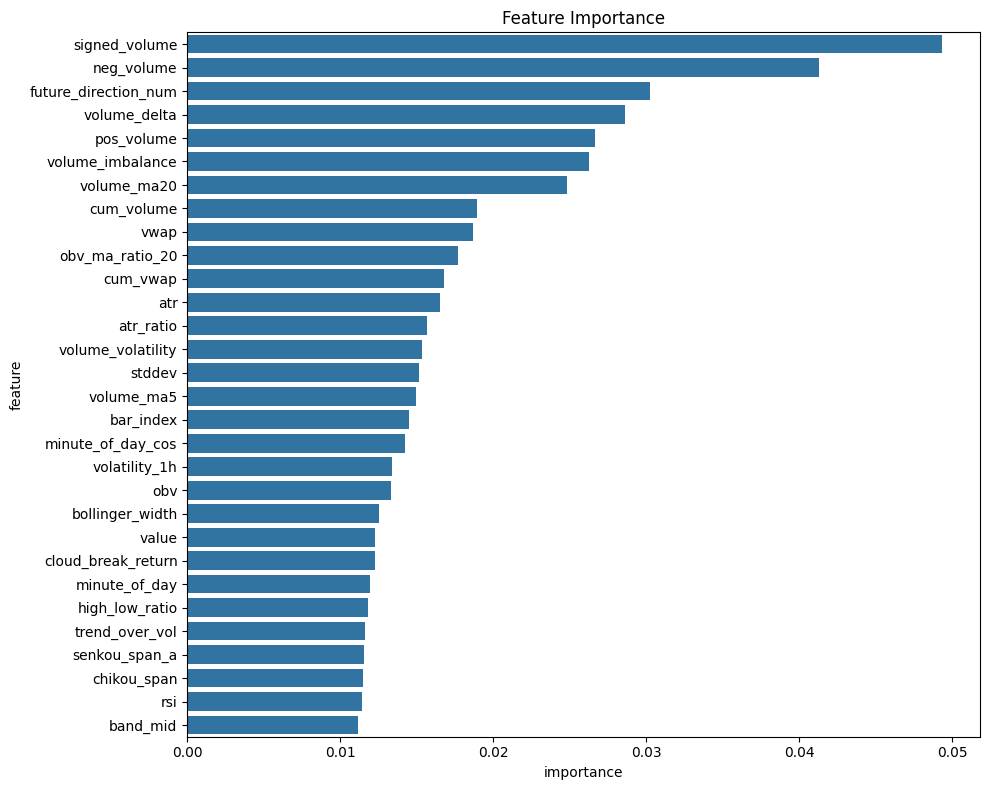

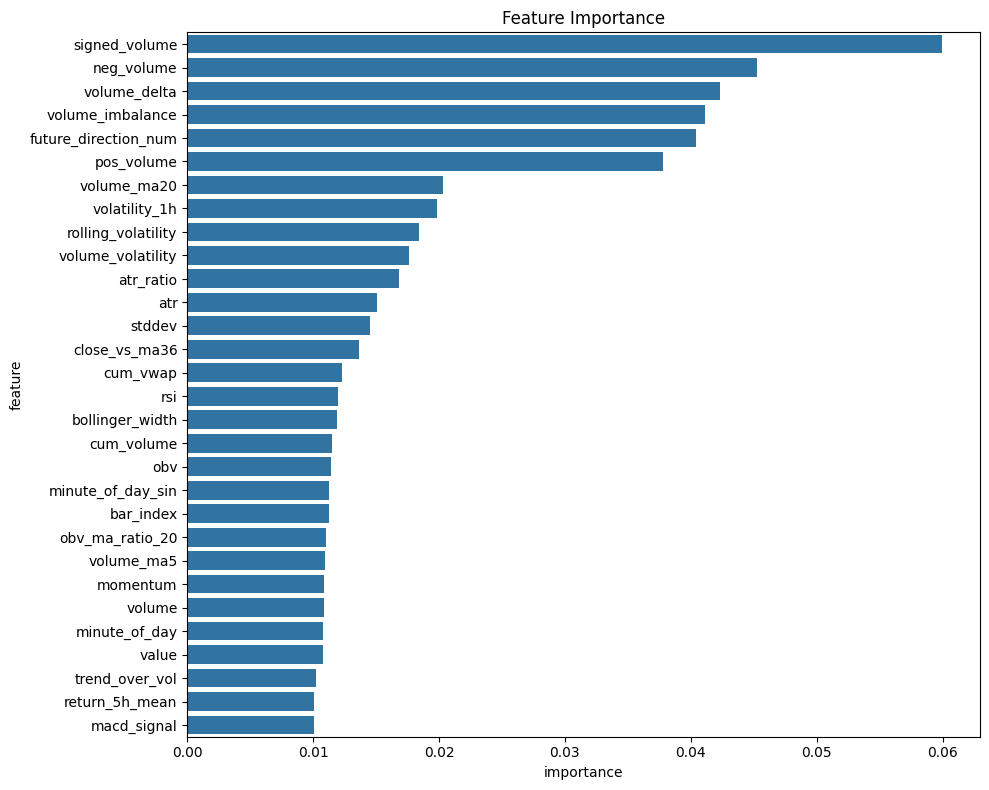

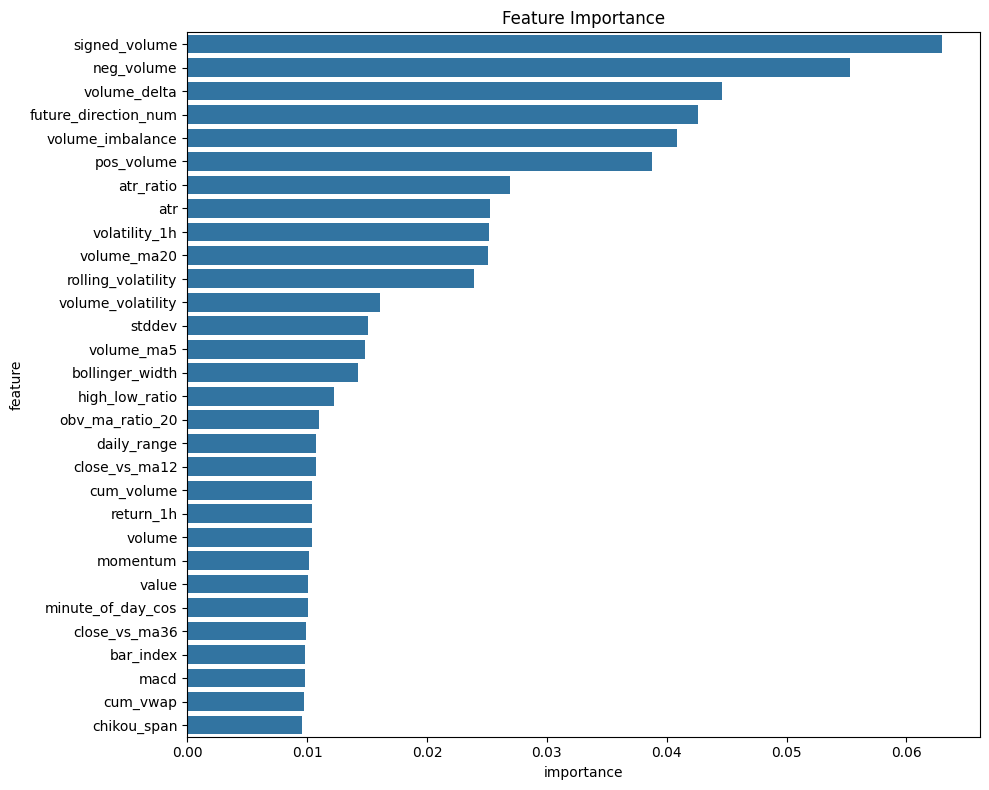

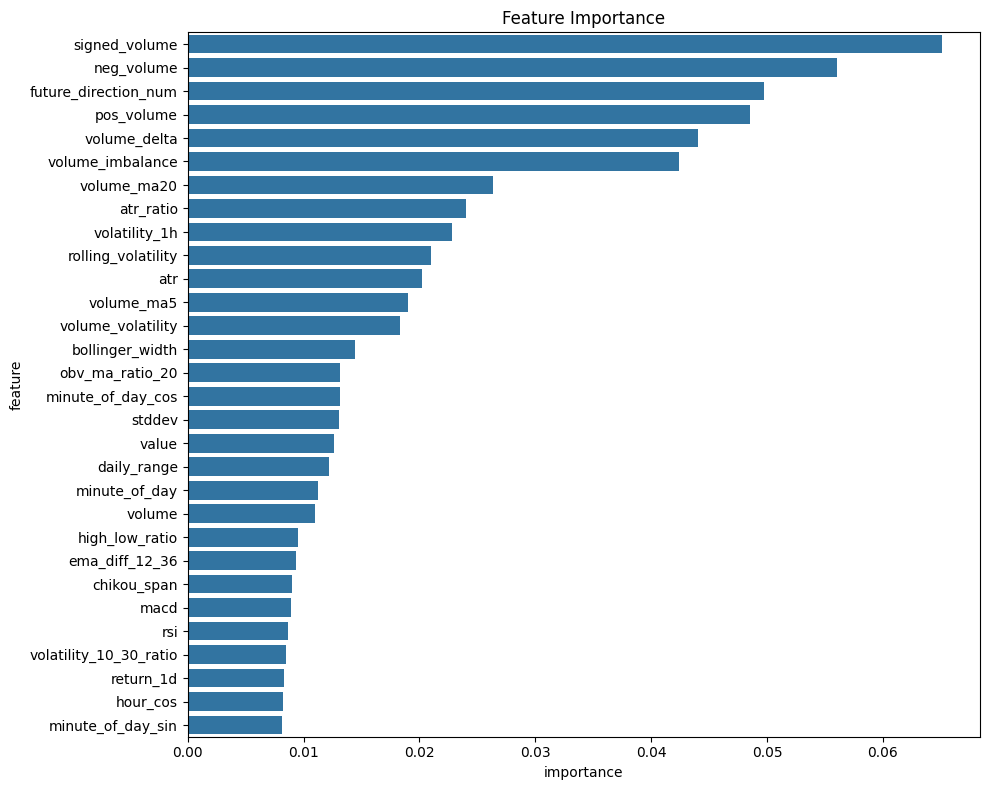

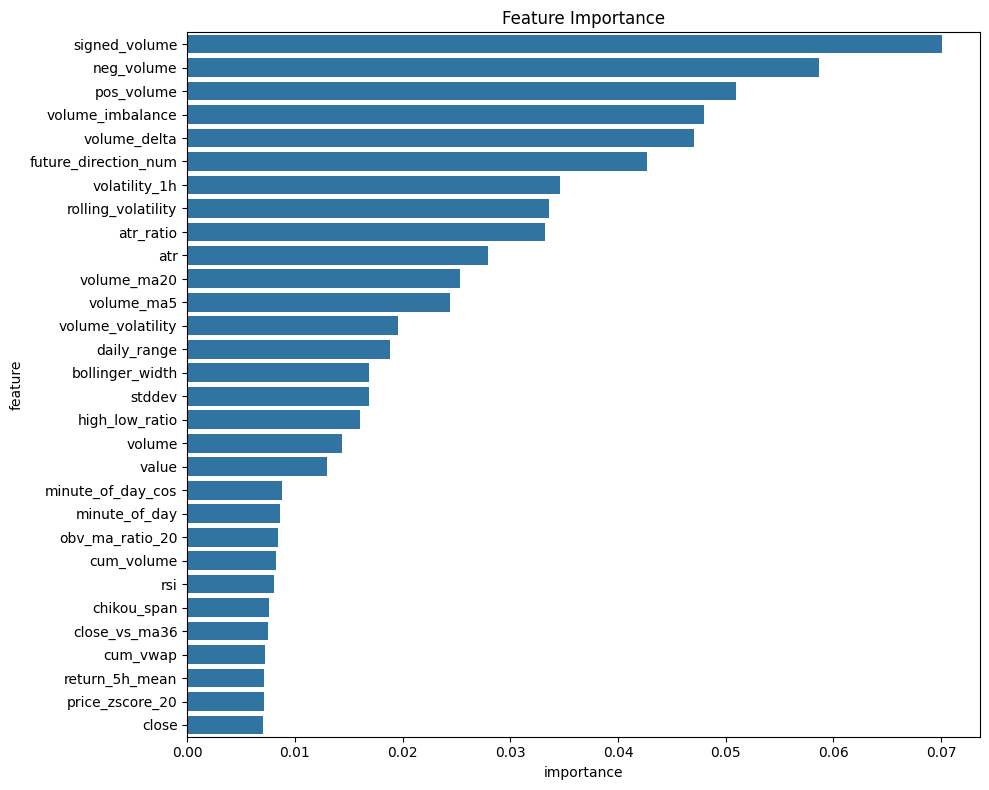

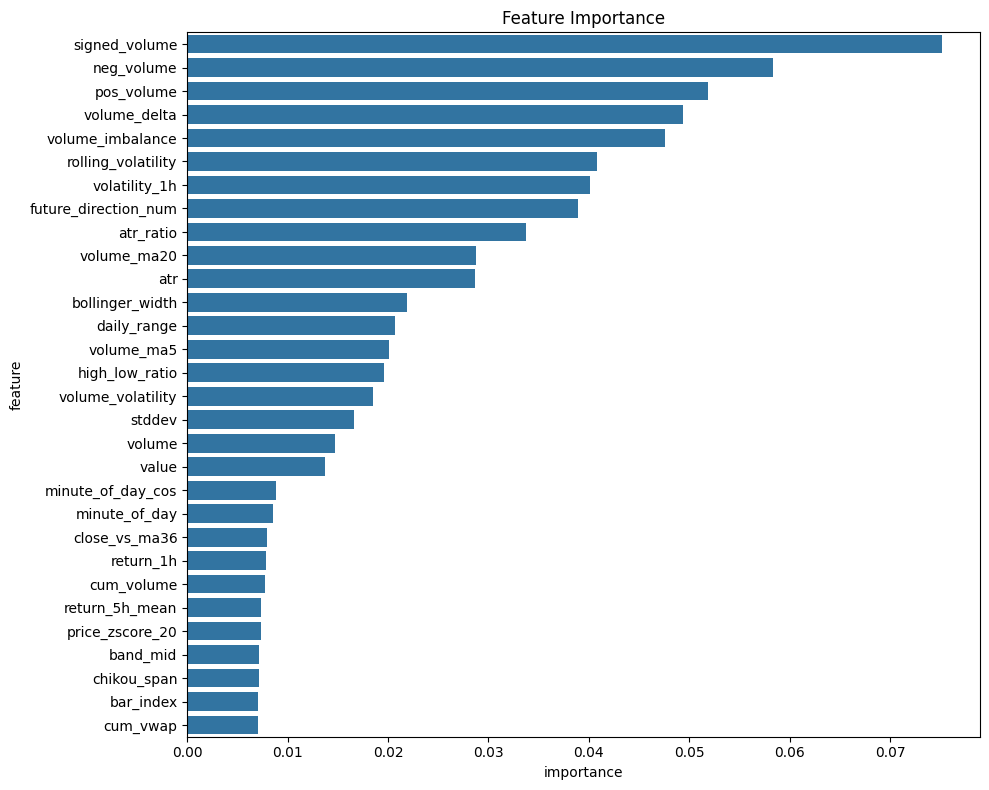

In [19]:

interval = "minute5"
count = 200
days = 93

DAY_COUNT = 288

periods = {
    "3_month": DAY_COUNT * 90,
    "2_month": DAY_COUNT * 60,
    "1_month": DAY_COUNT * 30,
    "3_week":  DAY_COUNT * 21,
    "2_week":  DAY_COUNT * 14,
    "1_week":  DAY_COUNT * 7,
}

upbit = ExChangeUpbit()
upbit.set_ticker("KRW-BTC")

end_dt = datetime.datetime.now()
start_dt = end_dt - datetime.timedelta(days=days)

dfs = []
to = end_dt
max_call = int((days * 24 * 12) / count) + 2

for _ in range(max_call):
    df = upbit.get_ohlcv(
        interval=interval,
        date=to.strftime("%Y-%m-%d %H:%M:%S"),
        count=count
    )

    if df is None or df.empty:
        break

    dfs.append(df)

    oldest_dt = df["datetime"].iloc[0]

    # 30일 이전이면 종료
    if oldest_dt <= start_dt:
        break

    # 다음 호출 기준점
    to = oldest_dt - datetime.timedelta(minutes=5)

df_combined = (
    pd.concat(dfs)
    .drop_duplicates(subset="datetime")
    .sort_values("datetime")
    .reset_index(drop=True)
)

calculator = ExChangeCalculator(df_combined)
df = apply_all_features(calculator)
df = create_target(df, horizon=3)  # 15분 뒤 기준

df_1w  = cut_by_days(end_dt, df, 7)
df_2w  = cut_by_days(end_dt, df, 14)
df_3w  = cut_by_days(end_dt, df, 21)
df_1m  = cut_by_days(end_dt, df, 30)
df_2m  = cut_by_days(end_dt, df, 60)
df_3m  = df

df_1w = get_feature_importance(df_1w)
plot_importance_pretty(df_1w)

df_2w = get_feature_importance(df_2w)
plot_importance_pretty(df_2w)

df_3w = get_feature_importance(df_3w)
plot_importance_pretty(df_3w)

df_1m = get_feature_importance(df_1m)
plot_importance_pretty(df_1m)

df_2m = get_feature_importance(df_2m)
plot_importance_pretty(df_2m)

df_3m = get_feature_importance(df_3m)
plot_importance_pretty(df_3m)

In [13]:
pip install jupyterlab_widgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 914.9/914.9 kB 9.1 MB/s  0:00:00

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [14]:
import shap

def get_feature_direction(df):

    df = df.copy()

    X = df.drop(columns=["datetime", "target", "future_close", "return"], errors="ignore")
    y = df["target"]

    X = X.select_dtypes(include=[np.number])
    X = X.replace([np.inf, -np.inf], np.nan).fillna(0)

    model = RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    )

    model.fit(X, y)

    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X)

    # shap version 대응
    if isinstance(shap_values, list):
        shap_matrix = shap_values[1]
    else:
        shap_matrix = shap_values[:, :, 1]

    shap_df = pd.DataFrame(shap_matrix, columns=X.columns)

    result = pd.DataFrame({
        "feature": X.columns,
        "mean_shap": shap_df.mean()
    })

    up = result.sort_values("mean_shap", ascending=False).head(15)
    down = result.sort_values("mean_shap").head(15)

    return up, down

In [15]:
up, down = get_feature_direction(df)

In [16]:
up

,feature,mean_shap
future_change_pct,future_change_pct,0.036145
future_change,future_change,0.030918
atr_ratio,atr_ratio,0.025032
volatility_1h,volatility_1h,0.021195
atr,atr,0.020834
rolling_volatility,rolling_volatility,0.017910
volume_ma5,volume_ma5,0.012672
volume_ma20,volume_ma20,0.011973
bollinger_width,bollinger_width,0.009702
daily_range,daily_range,0.009643


In [17]:
down

,feature,mean_shap
future_direction_num,future_direction_num,-1.425574e-03
volume_imbalance,volume_imbalance,-5.975514e-04
bullish_engulfing_flag,bullish_engulfing_flag,0.000000e+00
cdldojistar,cdldojistar,0.000000e+00
cdlconcealbabyswall,cdlconcealbabyswall,0.000000e+00
cdlhighwave,cdlhighwave,0.000000e+00
cdlxsidegap3methods,cdlxsidegap3methods,0.000000e+00
cdlupsidegap2crows,cdlupsidegap2crows,0.000000e+00
cdltristar,cdltristar,0.000000e+00
bearish_engulfing_flag,bearish_engulfing_flag,0.000000e+00
